# Введение

**Цель работы:** изучение методов классификации данных, реализованных в библиотеке Scikit-Learn, а также ознакомление с построением и обучением нейронных сетей с использованием TensorFlow и визуализацией процесса обучения средствами TensorBoard.

**Задачи работы:**

1. Выбрать датасет для классификации, провести анализ его структуры и выполнить необходимую предобработку данных.
2. Реализовать классификационные модели с использованием наивного байесовского классификатора, дерева решений, линейного дискриминантного анализа, метода опорных векторов и метода ближайших соседей.
3. Оценить качество классификации с помощью метрик Accuracy, Precision, Recall, F1-Score и AUC-ROC.
4. Исследовать влияние гиперпараметров на качество классификации и выполнить их подбор с использованием кросс-валидации.
5. Разработать и обучить полносвязную нейронную сеть с использованием TensorFlow, исследовать влияние её архитектуры и гиперпараметров на результаты обучения.
6. Визуализировать процесс обучения нейронной сети с помощью TensorBoard.
7. Провести сравнительный анализ результатов всех рассмотренных методов и определить наиболее эффективный подход для выбранного датасета.

# Выбор и анализ датасета

Для исследования методов классификации выбран датасет Titanic, содержащий информацию о пассажирах пассажирского лайнера «Титаник».

Задача заключается в прогнозировании выживания пассажира на основании его характеристик, таких как возраст, пол, класс билета, стоимость проезда и другие.

Датасет содержит следующие переменные:

| Признак | Описание |
|---|---|
| PassengerId | Уникальный идентификатор пассажира |
| Survived | Факт выживания (0 — не выжил, 1 — выжил) |
| Pclass | Класс билета (1 — первый, 2 — второй, 3 — третий) |
| Name | Имя пассажира |
| Sex | Пол пассажира |
| Age | Возраст пассажира |
| SibSp | Количество братьев, сестёр и супругов на борту |
| Parch | Количество родителей и детей на борту |
| Ticket | Номер билета |
| Fare | Стоимость билета |
| Cabin | Номер каюты |
| Embarked | Порт посадки (C — Шербур, Q — Квинстаун, S — Саутгемптон) |

Целевая переменная — **Survived**, принимающая два значения:
- 0 — пассажир не выжил;
- 1 — пассажир выжил.

Таким образом, рассматривается задача бинарной классификации.

In [200]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)


In [201]:
data = pd.read_csv('Titanic-Dataset.csv')

## Анализ размерности и типов данных

In [202]:
print("Размерность датасета:", data.shape)
data.info()

print("\nРаспределение классов:")
print(data['Survived'].value_counts().sort_index())

Размерность датасета: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Распределение классов:
Survived
0    549
1    342
Name: count, dtype: int64


### Выбор признаков

Для построения классификационных моделей исключим столбцы PassengerId, Name, Ticket и Cabin. Первые три содержат идентификационную или текстовую информацию, требующую дополнительной обработки, а Cabin имеет большое количество пропущенных значений.

В качестве признаков используются Pclass, Sex, Age, SibSp, Parch, Fare и Embarked. Целевая переменная — Survived.

In [203]:
X = data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin', 'Survived'])
y = data['Survived']

print("Размерность X:", X.shape)
print("Размерность y:", y.shape)
print("\nВыбранные признаки:")
print(X.columns.tolist())

Размерность X: (891, 7)
Размерность y: (891,)

Выбранные признаки:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


### Визуальная оценка разделимости классов

Для предварительной оценки разделимости классов строится матрица диаграмм рассеивания числовых признаков.

В качестве исследуемых признаков используются Age, SibSp, Parch и Fare. Цвет точек определяется значением целевой переменной Survived: 0 — пассажир не выжил (синий), 1 — пассажир выжил (оранжевый).

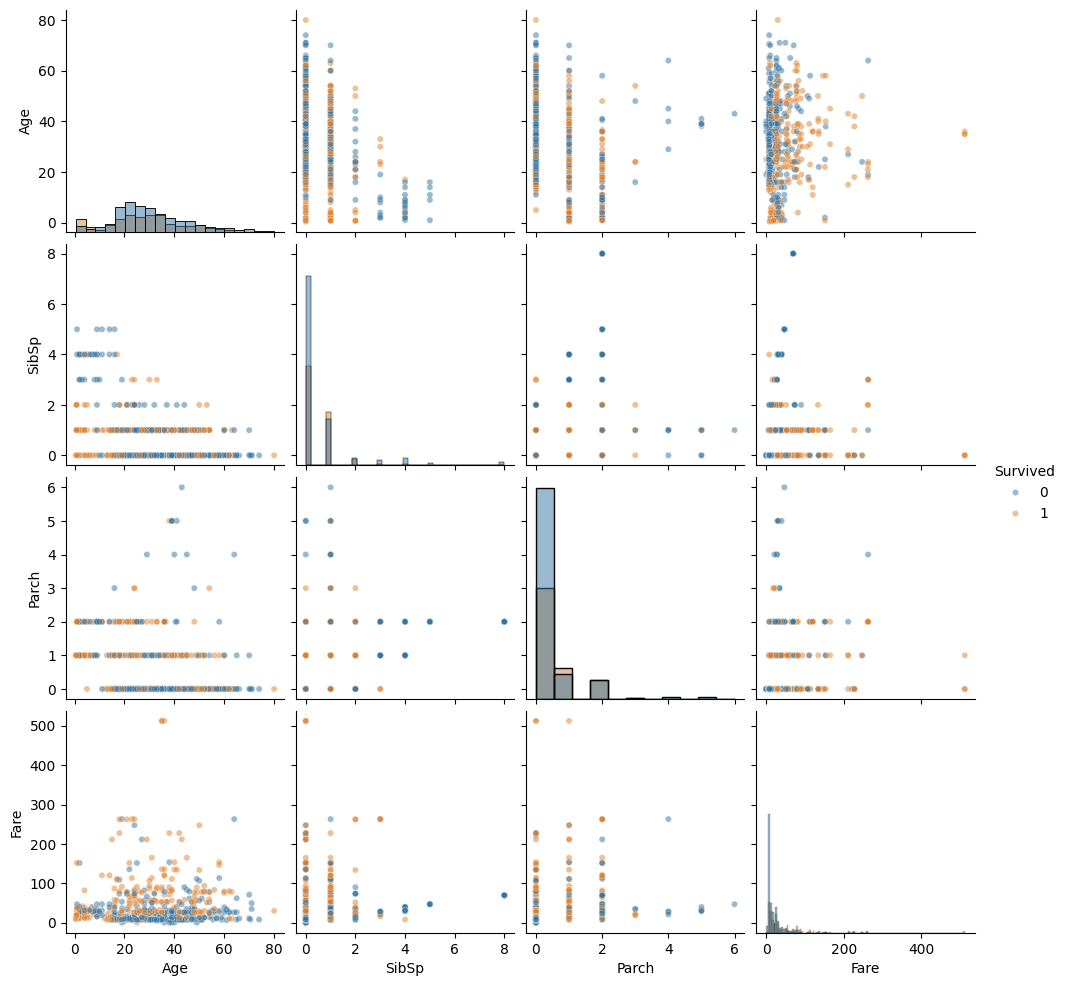

In [252]:
numeric_cols = ['Age', 'SibSp', 'Parch', 'Fare']

sns.pairplot(
    data=data,
    vars=numeric_cols,
    hue='Survived',
    palette={0: '#3274A1', 1: '#E1812C'},
    diag_kind='hist',
    plot_kws={'alpha': 0.5, 's': 20}
)

plt.show()

Вывод: по результатам построения матрицы диаграмм рассеивания установлено, что классы выживших и погибших пассажиров значительно пересекаются в пространстве рассматриваемых числовых признаков. Чётко выраженных границ между классами не наблюдается, что свидетельствует об их слабой разделимости в двумерных проекциях.

Для дополнительной оценки разделимости классов проводится анализ категориальных признаков Sex, Pclass и Embarked. Строятся столбчатые диаграммы, отражающие процентное соотношение выживших и погибших пассажиров внутри каждой категории.

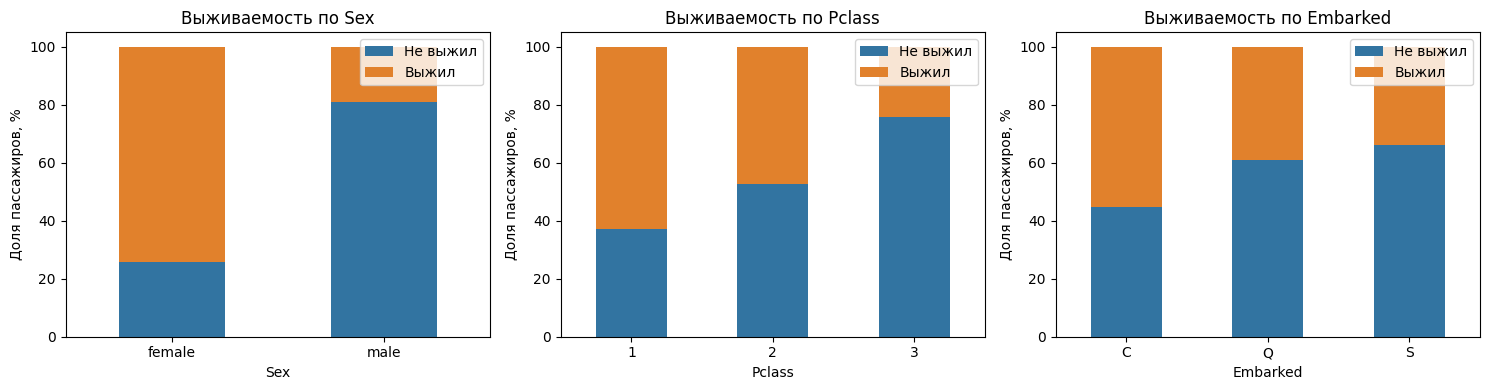

In [253]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['Sex', 'Pclass', 'Embarked']):
    proportions = pd.crosstab(
        data[col],
        data['Survived'],
        normalize='index'
    ) * 100

    proportions.plot(
        kind='bar',
        stacked=True,
        color=['#3274A1', '#E1812C'],
        ax=ax
    )

    ax.set_title(f'Выживаемость по {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Доля пассажиров, %')
    ax.legend(['Не выжил', 'Выжил'])
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Вывод: анализ категориальных признаков показал более выраженные различия в выживаемости пассажиров. Наибольшие различия наблюдаются по признаку Sex: доля выживших среди женщин составляет около 74%, среди мужчин — 19%. Также установлено, что вероятность выживания заметно различается в зависимости от класса обслуживания Pclass и порта посадки Embarked.

### Разбиение выборки

Датасет разделяется на обучающую (80%) и тестовую (20%) выборки. Для сохранения исходного соотношения классов используется стратификация по целевой переменной Survived.

In [204]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=67,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (712, 7)
Тестовая выборка: (179, 7)


### Обработка пропущенных значений

In [205]:
print("Количество пропусков по признакам:")
print(X.isnull().sum())

Количество пропусков по признакам:
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


Пропущенные значения признака Age заполняются медианой, поскольку она устойчива к выбросам. Для категориального признака Embarked используется наиболее часто встречающееся значение.

Параметры заполнения определяются по обучающей выборке и затем применяются к тестовой, что исключает утечку данных.

In [206]:
age_imputer = SimpleImputer(strategy='median')
embarked_imputer = SimpleImputer(strategy='most_frequent')

X_train['Age'] = age_imputer.fit_transform(X_train[['Age']]).ravel()
X_test['Age'] = age_imputer.transform(X_test[['Age']]).ravel()

X_train['Embarked'] = embarked_imputer.fit_transform(X_train[['Embarked']]).ravel()
X_test['Embarked'] = embarked_imputer.transform(X_test[['Embarked']]).ravel()

print("Пропуски в обучающей выборке:", X_train.isnull().sum().sum())
print("Пропуски в тестовой выборке:", X_test.isnull().sum().sum())

Пропуски в обучающей выборке: 0
Пропуски в тестовой выборке: 0


### Кодирование категориальных признаков

Для преобразования категориальных признаков в числовой формат используется One-Hot Encoding. Признаки Pclass и Embarked преобразуются в набор бинарных столбцов, а бинарный признак Sex кодируется значениями 0 и 1.

Кодировщик обучается на обучающей выборке, после чего применяется к тестовой.

In [207]:
X_train['Sex'] = X_train['Sex'].map({'male': 0, 'female': 1})
X_test['Sex'] = X_test['Sex'].map({'male': 0, 'female': 1})

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

categorical_cols = ['Pclass', 'Embarked']

train_encoded = encoder.fit_transform(X_train[categorical_cols])
test_encoded = encoder.transform(X_test[categorical_cols])

encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train = pd.concat([
    X_train.drop(columns=categorical_cols),
    pd.DataFrame(train_encoded, columns=encoded_cols, index=X_train.index)
], axis=1)

X_test = pd.concat([
    X_test.drop(columns=categorical_cols),
    pd.DataFrame(test_encoded, columns=encoded_cols, index=X_test.index)
], axis=1)

print("Размерность обучающей выборки:", X_train.shape)
print("Размерность тестовой выборки:", X_test.shape)

display(X_train.head())

Размерность обучающей выборки: (712, 11)
Размерность тестовой выборки: (179, 11)


,Sex,Age,SibSp,Parch,Fare,Pclass_1,Pclass_2,Pclass_3,Embarked_C,Embarked_Q,Embarked_S
90,0,29.0,0,0,8.0500,0.0,0.0,1.0,0.0,0.0,1.0
551,0,27.0,0,0,26.0000,0.0,1.0,0.0,0.0,0.0,1.0
192,1,19.0,1,0,7.8542,0.0,0.0,1.0,0.0,0.0,1.0
95,0,29.0,0,0,8.0500,0.0,0.0,1.0,0.0,0.0,1.0
668,0,43.0,0,0,8.0500,0.0,0.0,1.0,0.0,0.0,1.0


### Корреляционный анализ

Для оценки взаимосвязей между признаками построим корреляционную матрицу с использованием коэффициента корреляции Пирсона.

Анализ позволит выявить признаки с сильной линейной зависимостью. Корреляция рассчитывается по обучающей выборке, чтобы не использовать тестовые данные на этапе анализа.

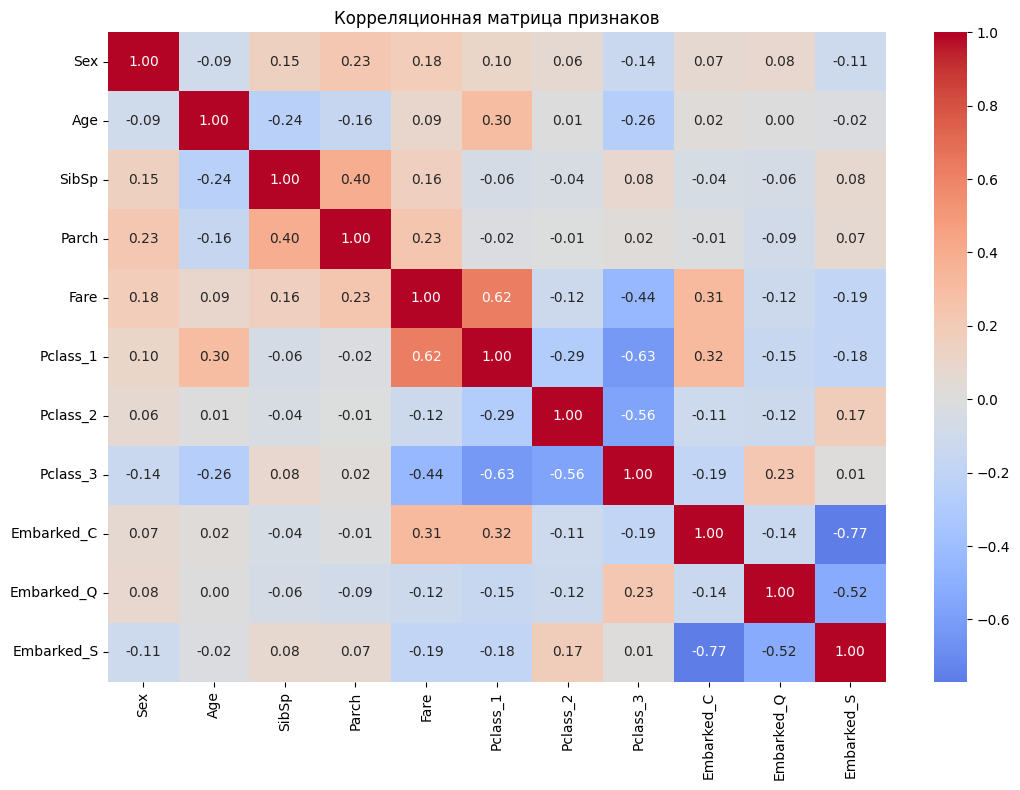

In [208]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    X_train.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Корреляционная матрица признаков')
plt.tight_layout()
plt.show()

Наиболее сильные корреляции наблюдаются между категориальными признаками, преобразованными методом One-Hot Encoding (до |r| = 0,77), что объясняется их взаимной исключительностью. Среди остальных признаков наиболее заметна положительная корреляция между стоимостью билета (Fare) и первым классом (Pclass_1), r = 0,62. Критических зависимостей, требующих дополнительного удаления признаков, не выявлено.

# Наивный байесовский классификатор (GaussianNB)

Наивный байесовский классификатор — вероятностный метод классификации, основанный на теореме Байеса и предположении об условной независимости признаков при известном классе.

Вероятность принадлежности объекта к классу определяется по формуле:

$$
P(C_k \mid X) = \frac{P(C_k)\,P(X \mid C_k)}{P(X)}
$$

где:
- $P(C_k \mid X)$ — вероятность принадлежности объекта к классу $C_k$ при известных признаках $X$;
- $P(C_k)$ — априорная вероятность класса;
- $P(X \mid C_k)$ — вероятность наблюдения признаков при условии принадлежности к классу;
- $P(X)$ — вероятность наблюдения признаков.

**GaussianNB** предполагает, что каждый признак внутри класса подчиняется нормальному распределению:

$$
P(x_i \mid C_k) =
\frac{1}{\sqrt{2\pi\sigma_{ik}^{2}}}
\exp\left(
-\frac{(x_i-\mu_{ik})^2}{2\sigma_{ik}^{2}}
\right)
$$

где $\mu_{ik}$ и $\sigma_{ik}^{2}$ — среднее значение и дисперсия признака $i$ для класса $C_k$.

**Обоснование выбора метода.** Для датасета Titanic выбран GaussianNB, поскольку среди признаков присутствуют непрерывные числовые переменные Age и Fare. Метод не требует масштабирования признаков. При этом часть переменных является бинарной или дискретной, поэтому предположение о нормальности выполняется не для всех признаков.

Остальные варианты менее подходящие:
- **MultinomialNB** — предназначен преимущественно для частотных данных.
- **ComplementNB** — ориентирован на частотные данные, особенно при дисбалансе классов.
- **BernoulliNB** — требует бинарных признаков, тогда как часть наших признаков непрерывная.

In [209]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

### Оценка качества GaussianNB

Для оценки качества классификации используются следующие метрики:

- **Accuracy** — доля правильно классифицированных пассажиров среди всех наблюдений.
- **Precision** — доля действительно выживших среди пассажиров, которых модель определила как выживших.
- **Recall** — доля правильно обнаруженных выживших среди всех действительно выживших пассажиров.
- **F1-score** — гармоническое среднее Precision и Recall, характеризующее баланс между ними.
- **ROC-AUC** — площадь под ROC-кривой, характеризующая способность модели различать классы при различных порогах классификации.

Положительным классом считается выживший пассажир (Survived = 1). Все метрики рассчитываются на тестовой выборке.

Дополнительно строится **матрица ошибок**, отображающая количество верно и ошибочно классифицированных пассажиров каждого класса: истинно положительные (TP), истинно отрицательные (TN), ложноположительные (FP) и ложноотрицательные (FN) предсказания.

In [210]:
y_proba_nb = nb_model.predict_proba(X_test)[:, 1]

nb_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_nb),
    'Precision': precision_score(y_test, y_pred_nb),
    'Recall': recall_score(y_test, y_pred_nb),
    'F1-score': f1_score(y_test, y_pred_nb),
    'ROC-AUC': roc_auc_score(y_test, y_proba_nb)
}

display(pd.DataFrame([nb_metrics], index=['GaussianNB']).round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
GaussianNB,0.827,0.788,0.754,0.77,0.865


Модель GaussianNB показала Accuracy = 0,827 и F1-score = 0,770, что свидетельствует о достаточно хорошем качестве классификации. Значение Recall = 0,754 указывает на то, что модель обнаруживает 75,4% выживших пассажиров. ROC-AUC = 0,865 свидетельствует о хорошей способности модели различать классы.

### Матрица ошибок

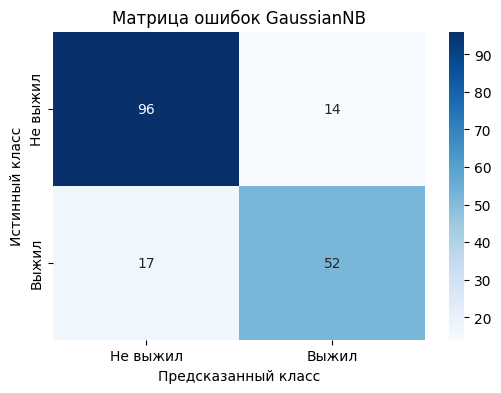

In [211]:
cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не выжил', 'Выжил'],
    yticklabels=['Не выжил', 'Выжил']
)

plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок GaussianNB')
plt.show()

### Вывод
Согласно матрице ошибок, модель правильно классифицировала 96 невыживших и 52 выживших пассажиров. При этом 14 невыживших были ошибочно отнесены к выжившим, а 17 выживших — к невыжившим.

Таким образом, модель правильно классифицировала 82,7% пассажиров и продемонстрировала хорошую способность различать классы, однако допустила несколько больше ошибок при обнаружении выживших.

# Дерево решений (Decision Tree)

**Дерево решений** — алгоритм классификации, который последовательно разделяет данные на группы на основе значений признаков. Во внутренних узлах дерева проверяются условия, а в конечных узлах (листьях) определяется предсказанный класс.

Для выбора оптимального разделения используется критерий неоднородности. Одним из наиболее распространённых является **индекс Джини**:

$$
Gini = 1 - \sum_{k=1}^{K} p_k^2
$$

где:
- $K$ — количество классов;
- $p_k$ — доля объектов класса $k$ в рассматриваемом узле.

Чем меньше значение индекса Джини, тем однороднее узел. Алгоритм выбирает разделения, которые максимально уменьшают неоднородность дочерних узлов с учётом их размеров.

**Особенности метода.** Дерево решений не требует нормального распределения и масштабирования признаков, способно выявлять нелинейные зависимости. Однако при чрезмерной глубине дерева возможно переобучение.

In [212]:
dt_model = DecisionTreeClassifier(random_state=67)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

**Визуализация дерева решений**

Для интерпретации работы классификатора визуализируем первые три уровня обученного дерева решений. Это позволит определить, какие признаки используются при первоначальном разделении пассажиров и по каким условиям формируются прогнозы.

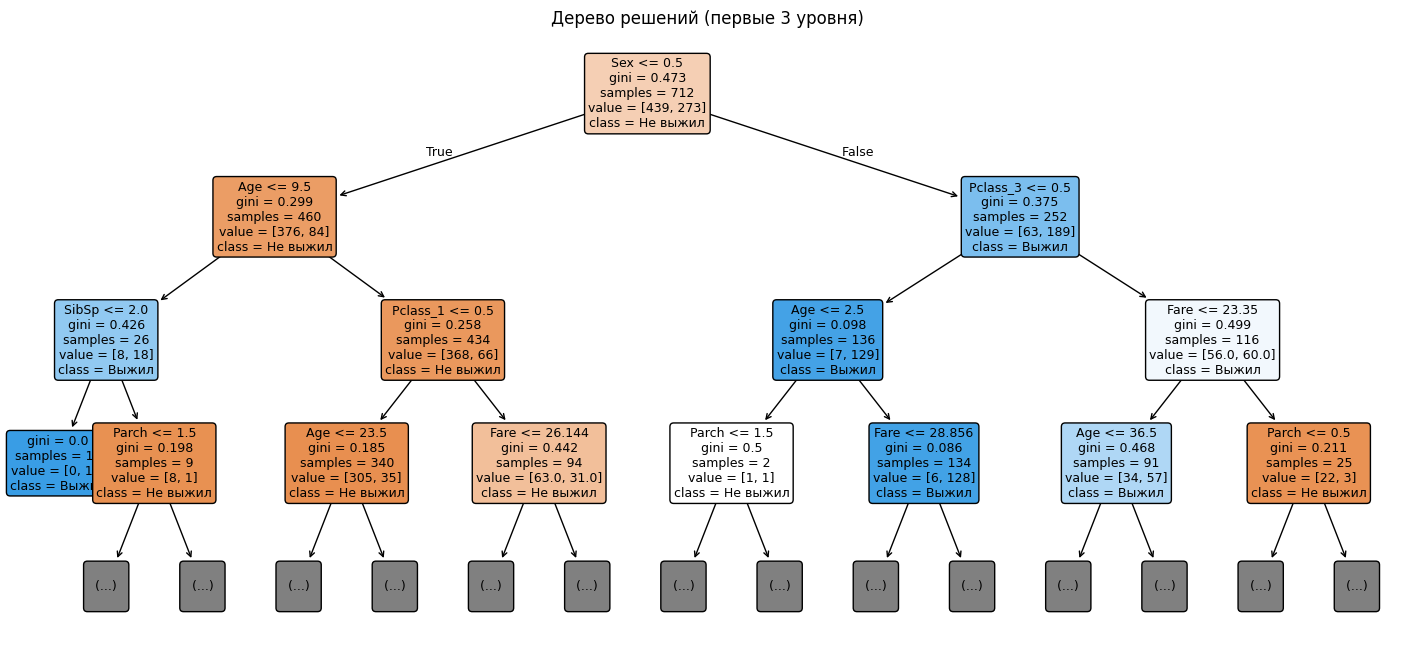

In [213]:
plt.figure(figsize=(18, 8))

plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=['Не выжил', 'Выжил'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title('Дерево решений (первые 3 уровня)')
plt.show()

In [214]:
print("Глубина дерева:", dt_model.get_depth())
print("Количество листьев:", dt_model.get_n_leaves())

Глубина дерева: 18
Количество листьев: 164


### Анализ структуры дерева
Построенное дерево решений имеет глубину 18 и содержит 164 листа. Наиболее значимым признаком для первоначального разделения оказался пол пассажира (Sex). На следующем уровне используются возраст (Age) и класс билета (Pclass).

Визуализация показывает, что вероятность выживания значительно различается в зависимости от пола, возраста и класса пассажира. Большая глубина и количество листьев указывают на риск переобучения, который необходимо проверить сравнением качества на обучающей и тестовой выборках.

#### Проверка на переобучение

In [215]:
print("Accuracy (train):", round(dt_model.score(X_train, y_train), 3))
print("Accuracy (test):", round(dt_model.score(X_test, y_test), 3))

Accuracy (train): 0.978
Accuracy (test): 0.76


Сравнение качества на обучающей и тестовой выборках выявило выраженное переобучение: Accuracy на обучающей выборке составила 0,978, а на тестовой — 0,760. Разница в 21,8 процентного пункта свидетельствует о недостаточной обобщающей способности модели. В дальнейшем для снижения переобучения будет выполнен подбор гиперпараметров, ограничивающих сложность дерева.

### Оценка качества Decision Tree

In [216]:
y_proba_dt = dt_model.predict_proba(X_test)[:, 1]

dt_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt),
    'Recall': recall_score(y_test, y_pred_dt),
    'F1-score': f1_score(y_test, y_pred_dt),
    'ROC-AUC': roc_auc_score(y_test, y_proba_dt)
}

display(pd.DataFrame([dt_metrics], index=['Decision Tree']).round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Decision Tree,0.76,0.703,0.652,0.677,0.74


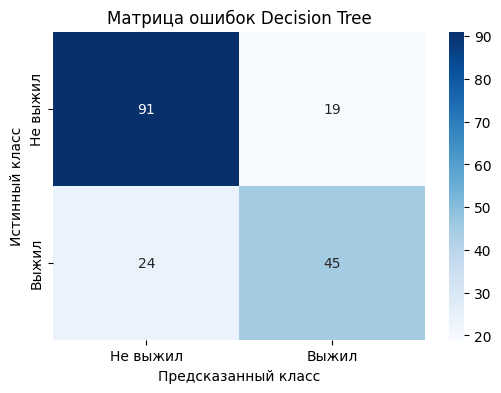

In [217]:
cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не выжил', 'Выжил'],
    yticklabels=['Не выжил', 'Выжил']
)

plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок Decision Tree')
plt.show()

### Вывод
Модель Decision Tree показала Accuracy = 0,760, Precision = 0,703, Recall = 0,652, F1-score = 0,677 и ROC-AUC = 0,740.

Согласно матрице ошибок, модель правильно классифицировала 91 невыжившего и 45 выживших пассажиров. При этом 19 невыживших были ошибочно отнесены к выжившим, а 24 выживших — к невыжившим.

# Линейный дискриминантный анализ (LDA)

**Линейный дискриминантный анализ (LDA)** — метод классификации, основанный на поиске линейных границ между классами. Алгоритм использует средние значения признаков и общую ковариационную матрицу для определения принадлежности объекта к классу.

Дискриминантная функция для класса $k$ имеет вид:

$$
\delta_k(x) = x^T \Sigma^{-1}\mu_k
-\frac{1}{2}\mu_k^T\Sigma^{-1}\mu_k
+\ln P(C_k)
$$

где:
- $x$ — вектор признаков объекта;
- $\mu_k$ — вектор средних значений признаков класса $k$;
- $\Sigma$ — общая ковариационная матрица;
- $P(C_k)$ — априорная вероятность класса.

Объект относится к классу с наибольшим значением дискриминантной функции.

LDA предполагает многомерное нормальное распределение признаков внутри каждого класса и равенство ковариационных матриц классов. Метод не требует обязательного масштабирования, однако его качество может снижаться при нарушении этих предположений.

In [218]:
lda_model = LinearDiscriminantAnalysis()

lda_model.fit(X_train, y_train)

y_pred_lda = lda_model.predict(X_test)

### Оценка качества LDA

In [219]:
y_proba_lda = lda_model.predict_proba(X_test)[:, 1]

lda_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_lda),
    'Precision': precision_score(y_test, y_pred_lda),
    'Recall': recall_score(y_test, y_pred_lda),
    'F1-score': f1_score(y_test, y_pred_lda),
    'ROC-AUC': roc_auc_score(y_test, y_proba_lda)
}

display(pd.DataFrame([lda_metrics], index=['LDA']).round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
LDA,0.765,0.721,0.638,0.677,0.838


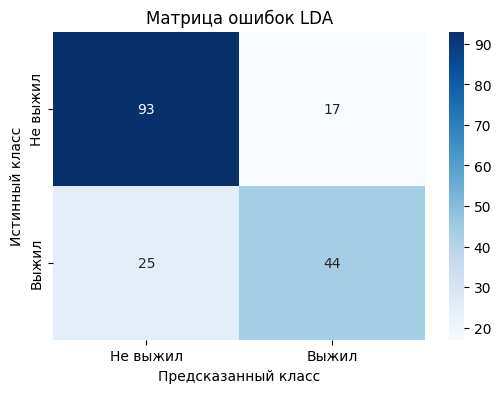

In [220]:
cm_lda = confusion_matrix(y_test, y_pred_lda)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lda,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не выжил', 'Выжил'],
    yticklabels=['Не выжил', 'Выжил']
)

plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок LDA')
plt.show()

### Вывод
Модель LDA показала Accuracy = 0,765, Precision = 0,721, Recall = 0,638, F1-score = 0,677 и ROC-AUC = 0,838.

Согласно матрице ошибок, модель правильно классифицировала 93 невыживших и 44 выживших пассажиров. При этом 17 невыживших были ошибочно отнесены к выжившим, а 25 выживших — к невыжившим. Значение Recall = 0,638 указывает на то, что модель обнаружила только 63,8% действительно выживших пассажиров.

# Метод опорных векторов (Support Vector Machines, SVM)

**Метод опорных векторов (SVM)** — алгоритм классификации, который строит разделяющую границу между классами таким образом, чтобы максимизировать расстояние от неё до ближайших обучающих объектов. Эти объекты называются опорными векторами.

Для линейного случая разделяющая гиперплоскость задаётся уравнением:

$$
w^Tx+b=0
$$

где:
- $w$ — вектор весовых коэффициентов;
- $x$ — вектор признаков объекта;
- $b$ — свободный коэффициент.

При линейно разделимых данных алгоритм максимизирует зазор между классами, что эквивалентно минимизации:

$$
\frac{1}{2}\|w\|^2
$$

При наличии ошибок классификации используется мягкий зазор, допускающий нарушения границы разделения.

Для построения нелинейных границ SVM использует **ядерные функции**. Например, радиальная базисная функция (RBF):

$$
K(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|^2)
$$

где $\gamma$ определяет влияние отдельных обучающих объектов на разделяющую границу.

### Масштабирование
Метод SVM чувствителен к масштабу признаков, поэтому перед обучением необходимо выполнить стандартизацию. Для этого используется StandardScaler, который преобразует признаки так, чтобы их среднее значение было равно 0, а стандартное отклонение — 1. Масштабирование и классификатор объединяются в Pipeline, что обеспечивает применение одинакового преобразования к обучающей и тестовой выборкам без утечки данных.

In [221]:
svm_model = make_pipeline(
    StandardScaler(),
    SVC(probability=True, random_state=67)
)

In [222]:
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

### Оценка качества SVM

In [223]:
y_proba_svm = svm_model.predict_proba(X_test)[:, 1]

svm_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'Precision': precision_score(y_test, y_pred_svm),
    'Recall': recall_score(y_test, y_pred_svm),
    'F1-score': f1_score(y_test, y_pred_svm),
    'ROC-AUC': roc_auc_score(y_test, y_proba_svm)
}

display(pd.DataFrame([svm_metrics], index=['SVM']).round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
SVM,0.782,0.759,0.638,0.693,0.838


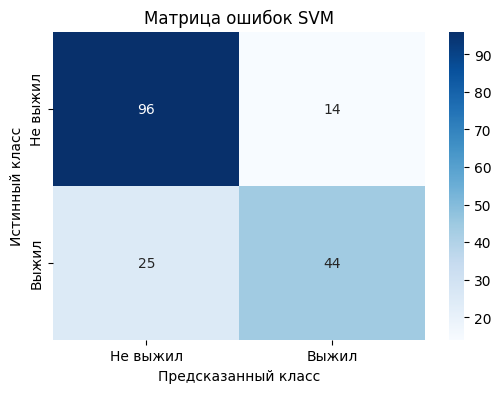

In [224]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не выжил', 'Выжил'],
    yticklabels=['Не выжил', 'Выжил']
)

plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок SVM')
plt.show()

### Вывод
Модель SVM показала Accuracy = 0,782, Precision = 0,759, Recall = 0,638, F1-score = 0,693 и ROC-AUC = 0,838.

Согласно матрице ошибок, модель правильно классифицировала 96 невыживших и 44 выживших пассажиров. При этом 14 невыживших были ошибочно отнесены к выжившим, а 25 выживших — к невыжившим.

Значение Precision = 0,759 указывает на то, что 75,9% пассажиров, определённых моделью как выжившие, действительно выжили. При этом Recall = 0,638 свидетельствует о том, что модель обнаружила только 63,8% всех выживших пассажиров.

# Метод k ближайших соседей (k-Nearest Neighbors, kNN)

**Метод k ближайших соседей (kNN)** — алгоритм классификации, который определяет класс нового объекта на основе классов его ближайших соседей в пространстве признаков. Объект относится к классу, наиболее часто встречающемуся среди k ближайших наблюдений.

Для определения близости объектов обычно используется **евклидово расстояние**:

$$
d(x_i,x_j)=\sqrt{\sum_{m=1}^{n}(x_{im}-x_{jm})^2}
$$

где:
- $x_i$, $x_j$ — сравниваемые объекты;
- $n$ — количество признаков;
- $x_{im}$, $x_{jm}$ — значения признака $m$ для соответствующих объектов.

kNN не строит явную математическую модель на этапе обучения, а сохраняет обучающие данные и использует их при классификации новых объектов. Метод чувствителен к масштабу признаков и выбору количества соседей k.

### Масштабирование
Метод kNN чувствителен к масштабу признаков, поскольку классификация основана на вычислении расстояний между объектами. Поэтому перед обучением выполняется стандартизация с помощью **StandardScaler**, приводящая признаки к нулевому среднему и единичному стандартному отклонению. Масштабирование и классификатор объединяются в **Pipeline**, что предотвращает утечку данных и обеспечивает одинаковую обработку обучающей и тестовой выборок.

In [225]:
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

In [226]:
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

### Оценка качества kNN

In [227]:
y_proba_knn = knn_model.predict_proba(X_test)[:, 1]

knn_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_knn),
    'Precision': precision_score(y_test, y_pred_knn),
    'Recall': recall_score(y_test, y_pred_knn),
    'F1-score': f1_score(y_test, y_pred_knn),
    'ROC-AUC': roc_auc_score(y_test, y_proba_knn)
}

display(pd.DataFrame([knn_metrics], index=['kNN']).round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
kNN,0.788,0.782,0.623,0.694,0.818


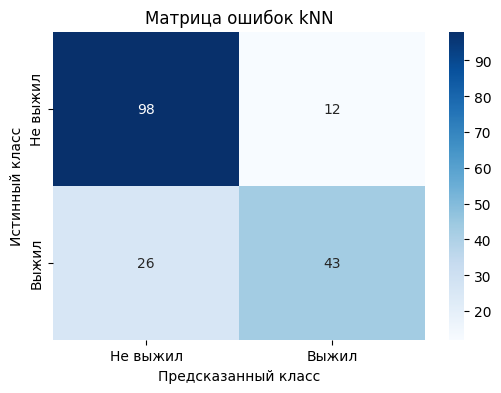

In [228]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Не выжил', 'Выжил'],
    yticklabels=['Не выжил', 'Выжил']
)

plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок kNN')
plt.show()

### Вывод
Модель kNN показала Accuracy = 0,788, Precision = 0,782, Recall = 0,623, F1-score = 0,694 и ROC-AUC = 0,818.

Согласно матрице ошибок, модель правильно классифицировала 98 невыживших и 43 выживших пассажиров. При этом 12 невыживших были ошибочно отнесены к выжившим, а 26 выживших — к невыжившим.

Значение Precision = 0,782 указывает на то, что 78,2% пассажиров, определённых моделью как выжившие, действительно выжили. При этом Recall = 0,623 свидетельствует о том, что модель обнаружила только 62,3% всех выживших пассажиров.

# Сравнительный анализ результатов классификации

In [229]:
results = pd.DataFrame({
    'GaussianNB': nb_metrics,
    'Decision Tree': dt_metrics,
    'LDA': lda_metrics,
    'SVM': svm_metrics,
    'kNN': knn_metrics
}).T

display(results.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
GaussianNB,0.827,0.788,0.754,0.770,0.865
Decision Tree,0.760,0.703,0.652,0.677,0.740
LDA,0.765,0.721,0.638,0.677,0.838
SVM,0.782,0.759,0.638,0.693,0.838
kNN,0.788,0.782,0.623,0.694,0.818


### Визуальное сравнение

<Figure size 1200x600 with 0 Axes>

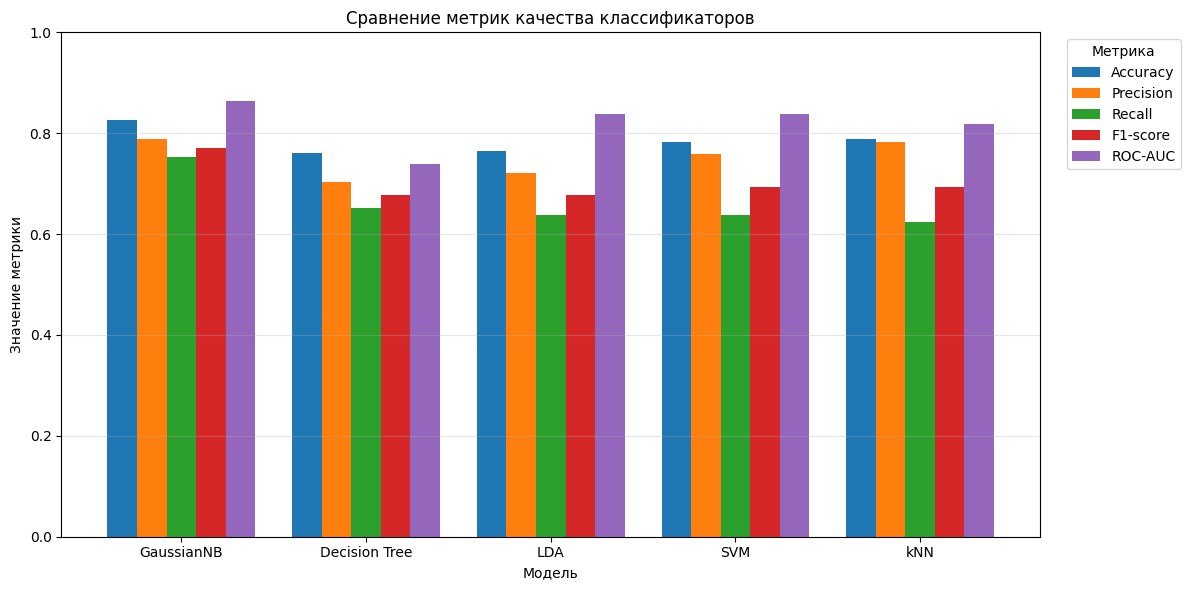

In [230]:
plt.figure(figsize=(12, 6))

results.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Сравнение метрик качества классификаторов')
plt.xlabel('Модель')
plt.ylabel('Значение метрики')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Метрика', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### ROC-кривые

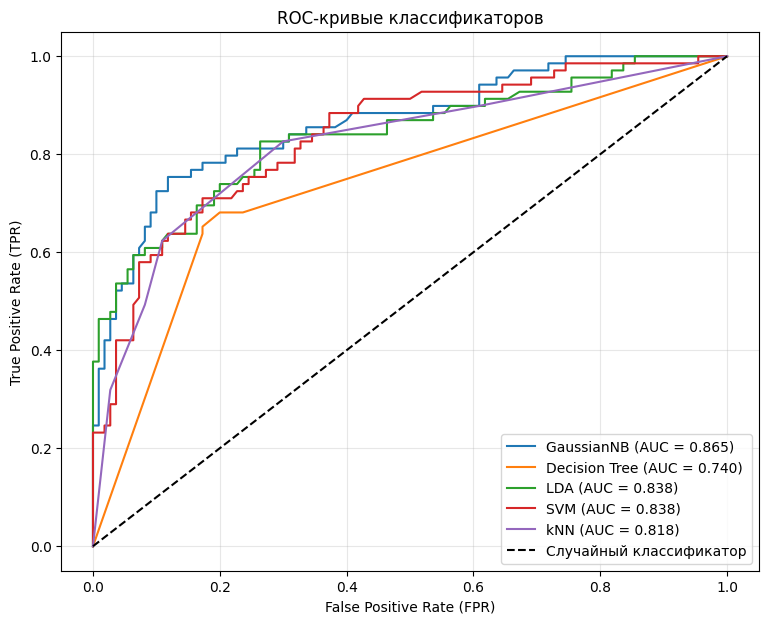

In [231]:
models_proba = {
    'GaussianNB': y_proba_nb,
    'Decision Tree': y_proba_dt,
    'LDA': y_proba_lda,
    'SVM': y_proba_svm,
    'kNN': y_proba_knn
}

plt.figure(figsize=(9, 7))

for name, proba in models_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор')

plt.title('ROC-кривые классификаторов')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

Анализ ROC-кривых показал, что все исследованные классификаторы обладают способностью различать выживших и невыживших пассажиров, поскольку их кривые располагаются выше линии случайного классификатора.

Наибольшее значение ROC-AUC продемонстрировала модель GaussianNB (0,865), ROC-кривая которой преимущественно располагается выше остальных. Модели LDA и SVM показали одинаковые значения ROC-AUC = 0,838, несколько уступая GaussianNB. Метод kNN получил ROC-AUC = 0,818, а наименьшее значение наблюдается у Decision Tree (0,740).

Таким образом, GaussianNB обеспечивает наилучшую способность различать классы при изменении порога классификации, тогда как Decision Tree демонстрирует наименее эффективное разделение.

# Общий вывод по сравнительному анализу классификаторов
В ходе исследования были обучены и оценены пять методов классификации: GaussianNB, Decision Tree, LDA, SVM и kNN. Сравнение проводилось на одной тестовой выборке с использованием метрик Accuracy, Precision, Recall, F1-score и ROC-AUC.

Наилучшие результаты по всем пяти метрикам продемонстрировала модель **GaussianNB**: Accuracy = 0,827, F1-score = 0,770 и ROC-AUC = 0,865. Это свидетельствует о её высокой эффективности при решении рассматриваемой задачи классификации.

Модели kNN, SVM и LDA показали близкие результаты по точности классификации, однако характеризуются относительно невысокими значениями Recall (0,623–0,638), что указывает на недостаточную полноту обнаружения выживших пассажиров.

Наименьшее качество по совокупности метрик продемонстрировало дерево решений. Дополнительный анализ выявил его выраженное переобучение: Accuracy на обучающей выборке составила 0,978, а на тестовой — 0,760.

Визуальное сравнение метрик и анализ ROC-кривых подтвердили полученные результаты. Таким образом, **GaussianNB признан наиболее эффективным классификатором среди исследованных моделей с параметрами по умолчанию**.

# Исследование влияния гиперпараметров на качество классификации

Оптимизация проводится с использованием **GridSearchCV**, осуществляющего перебор заданных комбинаций гиперпараметров с применением кросс-валидации. В качестве основной метрики оптимизации используется F1-score, учитывающая баланс между точностью и полнотой классификации.

Подбор параметров выполняется исключительно на обучающей выборке, что позволяет избежать использования тестовых данных при настройке моделей. После определения оптимальных параметров качество классификаторов оценивается на тестовой выборке по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC.

Дополнительно исследуется влияние отдельных гиперпараметров на качество классификации, а полученные результаты сравниваются с показателями исходных моделей.

### Подбор гиперпараметров GaussianNB

Классификатор GaussianNB имеет два основных гиперпараметра:

- **priors** — задаёт априорные вероятности классов. По умолчанию принимает значение None, при котором вероятности определяются автоматически на основе частот классов в обучающей выборке.
- **var_smoothing** — добавляет небольшую величину к дисперсиям признаков для повышения численной устойчивости вычислений. По умолчанию составляет $10^{-9}$.

В рамках исследования будет изменяться **var_smoothing**, поскольку этот параметр может влиять на оценку вероятностей и качество классификации. Параметр priors оставим равным None, чтобы априорные вероятности определялись по обучающим данным.

Для исследования выбраны следующие значения:

$$
var\_smoothing \in \{10^{-12}, 10^{-10}, 10^{-9}, 10^{-8}, 10^{-6}, 10^{-4}, 10^{-2}, 1\}
$$

Такой диапазон позволяет оценить влияние различных уровней сглаживания на качество классификации — от очень слабого до значительного.

In [232]:
param_grid_nb = {
    'var_smoothing': [1e-12, 1e-10, 1e-9, 1e-8, 1e-6, 1e-4, 1e-2, 1]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

grid_nb = GridSearchCV(
    GaussianNB(),
    param_grid_nb,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)

grid_nb.fit(X_train, y_train)

print("Лучшие параметры:", grid_nb.best_params_)
print("Лучший F1-score (CV):", round(grid_nb.best_score_, 3))

Лучшие параметры: {'var_smoothing': 1e-06}
Лучший F1-score (CV): 0.669


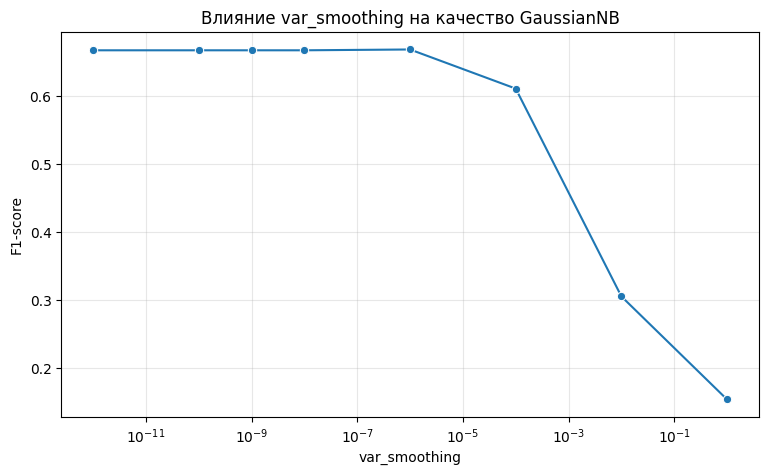

In [233]:
nb_cv_results = pd.DataFrame(grid_nb.cv_results_)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=nb_cv_results,
    x='param_var_smoothing',
    y='mean_test_score',
    marker='o'
)

plt.xscale('log')
plt.xlabel('var_smoothing')
plt.ylabel('F1-score')
plt.title('Влияние var_smoothing на качество GaussianNB')
plt.grid(alpha=0.3)
plt.show()

**Вывод:** В результате исследования установлено, что при значениях var_smoothing от $10^{-12}$ до $10^{-6}$ качество классификации практически не изменяется, а F1-score составляет около 0,669. При дальнейшем увеличении параметра наблюдается существенное снижение качества модели, связанное с чрезмерным сглаживанием дисперсий признаков.

По результатам GridSearchCV оптимальным выбрано значение var_smoothing = $10^{-6}$, при котором средний F1-score на кросс-валидации составил 0,669. Таким образом, для GaussianNB предпочтительны небольшие значения данного гиперпараметра.

### Оценка оптимизированной модели GaussianNB

In [234]:
nb_best = grid_nb.best_estimator_

y_pred_nb_best = nb_best.predict(X_test)
y_proba_nb_best = nb_best.predict_proba(X_test)[:, 1]

nb_best_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_nb_best),
    'Precision': precision_score(y_test, y_pred_nb_best),
    'Recall': recall_score(y_test, y_pred_nb_best),
    'F1-score': f1_score(y_test, y_pred_nb_best),
    'ROC-AUC': roc_auc_score(y_test, y_proba_nb_best)
}

display(pd.DataFrame([nb_best_metrics]).round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.832,0.8,0.754,0.776,0.865


### Сравнение результатов

In [235]:
nb_comparison = pd.DataFrame({
    'До оптимизации': nb_metrics,
    'После оптимизации': nb_best_metrics
}).T

display(nb_comparison.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
До оптимизации,0.827,0.788,0.754,0.770,0.865
После оптимизации,0.832,0.800,0.754,0.776,0.865


**Вывод:** Оптимизация гиперпараметра var_smoothing позволила незначительно повысить качество классификации GaussianNB. Значение Accuracy увеличилось с 0,827 до 0,832, Precision — с 0,788 до 0,800, а F1-score — с 0,770 до 0,776. При этом Recall (0,754) и ROC-AUC (0,865) остались неизменными.

Таким образом, подбор гиперпараметра обеспечил небольшое улучшение качества модели. Полученные результаты также подтверждают, что GaussianNB относительно устойчив к изменению var_smoothing в диапазоне малых значений.

### Подбор гиперпараметров Decision Tree

Дерево решений обладает несколькими гиперпараметрами, определяющими способ построения дерева и его сложность:

- **max_depth** — максимальная глубина дерева. Ограничение глубины позволяет уменьшить сложность модели и снизить риск переобучения.
- **min_samples_split** — минимальное количество объектов в узле, необходимое для его дальнейшего разделения. Увеличение параметра ограничивает создание новых ветвей.
- **min_samples_leaf** — минимальное количество объектов в конечном листе дерева. Увеличение параметра препятствует формированию листьев с небольшим количеством наблюдений.
- **criterion** — критерий оценки качества разделения узлов. В исследовании рассматриваются индекс Джини (gini) и энтропия (entropy).

Для исследования выбраны следующие значения:

| Гиперпараметр | Исследуемые значения |
|---|---|
| max_depth | 3, 5, 7, 10, 15 |
| min_samples_split | 2, 5, 10, 20 |
| min_samples_leaf | 1, 2, 5, 10 |
| criterion | gini, entropy |

In [236]:
param_grid_dt = {
    'max_depth': [3, 5, 7, 10, 15],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=67),
    param_grid_dt,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)

grid_dt.fit(X_train, y_train)

print("Лучшие параметры:", grid_dt.best_params_)
print("Лучший F1-score (CV):", round(grid_dt.best_score_, 3))

Лучшие параметры: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Лучший F1-score (CV): 0.767


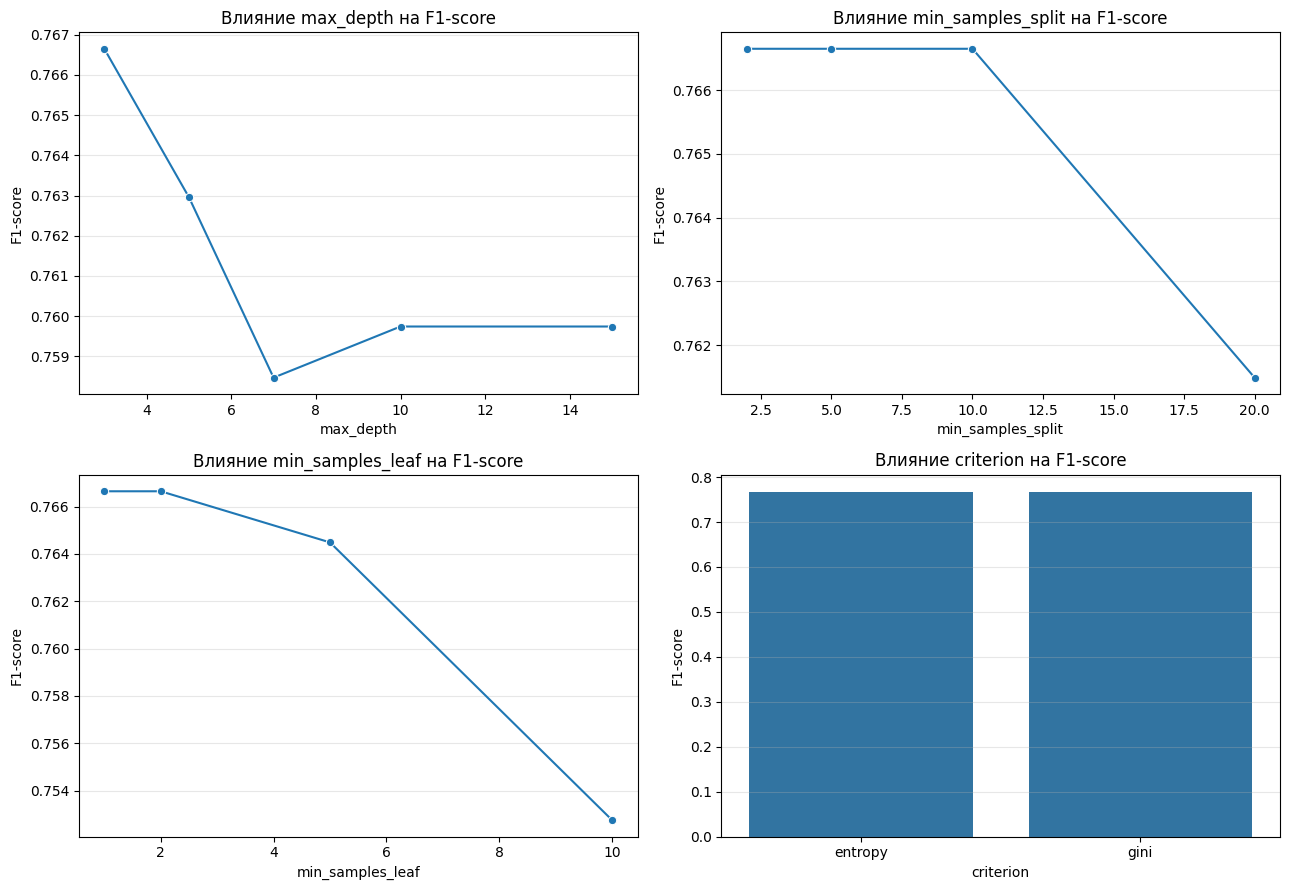

In [237]:
dt_cv_results = pd.DataFrame(grid_dt.cv_results_)

params = [
    'param_max_depth',
    'param_min_samples_split',
    'param_min_samples_leaf',
    'param_criterion'
]

titles = [
    'Влияние max_depth на F1-score',
    'Влияние min_samples_split на F1-score',
    'Влияние min_samples_leaf на F1-score',
    'Влияние criterion на F1-score'
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, param in enumerate(params):
    ax = axes.flat[i]

    results = dt_cv_results.groupby(
        param
    )['mean_test_score'].max().reset_index()

    if param == 'param_criterion':
        sns.barplot(
            data=results,
            x=param,
            y='mean_test_score',
            ax=ax
        )
    else:
        sns.lineplot(
            data=results,
            x=param,
            y='mean_test_score',
            marker='o',
            ax=ax
        )

    ax.set_title(titles[i])
    ax.set_xlabel(param.replace('param_', ''))
    ax.set_ylabel('F1-score')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод:** В результате исследования установлено, что наибольшее влияние на качество классификации оказывает максимальная глубина дерева. Лучшее значение F1-score (0,767) достигается при max_depth = 3, тогда как увеличение глубины приводит к снижению качества, что указывает на риск переобучения более сложных моделей.

Изменение min_samples_split оказывает незначительное влияние на результаты, а увеличение min_samples_leaf свыше 2 приводит к постепенному снижению F1-score. Критерии gini и entropy обеспечивают практически одинаковое качество классификации.

По результатам GridSearchCV выбрана следующая комбинация гиперпараметров: max_depth = 3, min_samples_split = 2, min_samples_leaf = 1, criterion = gini. Средний F1-score на кросс-валидации составил 0,767.

### Оценка оптимизированной модели Decision Tree

In [238]:
dt_best = grid_dt.best_estimator_

y_pred_dt_best = dt_best.predict(X_test)
y_proba_dt_best = dt_best.predict_proba(X_test)[:, 1]

dt_best_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_dt_best),
    'Precision': precision_score(y_test, y_pred_dt_best),
    'Recall': recall_score(y_test, y_pred_dt_best),
    'F1-score': f1_score(y_test, y_pred_dt_best),
    'ROC-AUC': roc_auc_score(y_test, y_proba_dt_best)
}

dt_comparison = pd.DataFrame({
    'До оптимизации': dt_metrics,
    'После оптимизации': dt_best_metrics
}).T

display(dt_comparison.round(3))

print("Accuracy (train):", round(dt_best.score(X_train, y_train), 3))
print("Accuracy (test):", round(dt_best.score(X_test, y_test), 3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
До оптимизации,0.760,0.703,0.652,0.677,0.740
После оптимизации,0.777,0.738,0.652,0.692,0.829


Accuracy (train): 0.844
Accuracy (test): 0.777


### Визуализация оптимизированного дерева решений

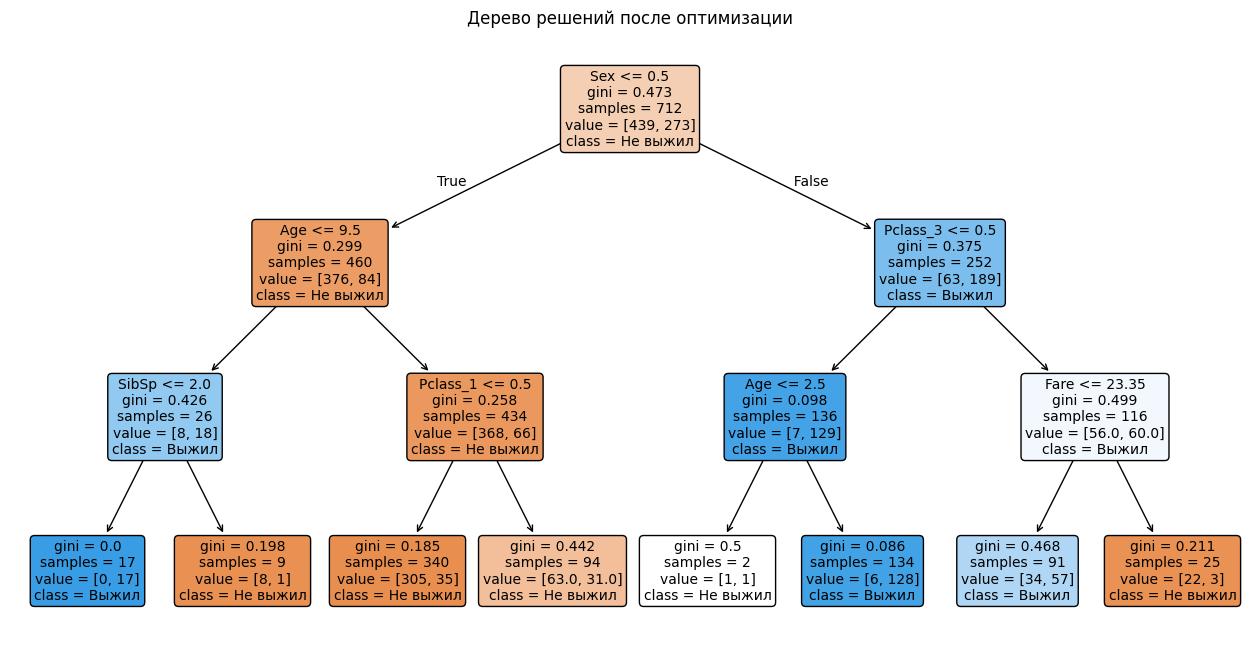

Глубина дерева: 3
Количество листьев: 8


In [239]:
plt.figure(figsize=(16, 8))

plot_tree(
    dt_best,
    feature_names=X_train.columns,
    class_names=['Не выжил', 'Выжил'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title('Дерево решений после оптимизации')
plt.show()

print("Глубина дерева:", dt_best.get_depth())
print("Количество листьев:", dt_best.get_n_leaves())

**Вывод:** Оптимизация гиперпараметров дерева решений позволила повысить качество классификации на тестовой выборке. Значение Accuracy увеличилось с 0,760 до 0,777, Precision — с 0,703 до 0,738, F1-score — с 0,677 до 0,692, а ROC-AUC — с 0,740 до 0,829. При этом Recall осталась неизменной и составила 0,652.

Наиболее существенным результатом стало уменьшение переобучения. После ограничения глубины дерева с 18 до 3 уровней Accuracy на обучающей выборке снизилась с 0,978 до 0,844, а на тестовой увеличилась с 0,760 до 0,777. Разница между показателями сократилась с 0,218 до 0,067.

Таким образом, подбор гиперпараметров позволил уменьшить сложность дерева, повысить его обобщающую способность и улучшить качество классификации.

# Подбор гиперпараметров LDA

Линейный дискриминантный анализ (LDA) имеет несколько гиперпараметров, влияющих на способ вычисления дискриминантных функций и оценку ковариационной матрицы.

В рамках исследования рассматриваются следующие гиперпараметры:

- **solver** — алгоритм вычисления параметров модели. Доступны три варианта:
  - **svd** — использует сингулярное разложение матрицы данных, не требуя явного вычисления ковариационной матрицы;
  - **lsqr** — использует метод наименьших квадратов;
  - **eigen** — использует разложение по собственным значениям.
- **shrinkage** — коэффициент регуляризации ковариационной матрицы. Позволяет повысить устойчивость оценок, особенно при наличии коррелирующих признаков. Значение 0 соответствует отсутствию регуляризации, а 1 — максимальному сглаживанию ковариационной матрицы в сторону диагональной матрицы со средней дисперсией.

Параметр shrinkage поддерживается только алгоритмами lsqr и eigen. Для solver = svd он не применяется.

Для исследования выбраны следующие комбинации:

| Гиперпараметр | Исследуемые значения |
|---|---|
| solver | svd, lsqr, eigen |
| shrinkage | auto, 0.1, 0.3, 0.5, 0.7, 1.0 |

Для алгоритма svd параметр shrinkage фиксируется на значении None. Для алгоритмов lsqr и eigen исследуются все перечисленные значения shrinkage.

In [240]:
param_grid_lda = [
    {
        'solver': ['svd'],
        'shrinkage': [None]
    },
    {
        'solver': ['lsqr', 'eigen'],
        'shrinkage': ['auto', 0.1, 0.3, 0.5, 0.7, 1.0]
    }
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

grid_lda = GridSearchCV(
    LinearDiscriminantAnalysis(),
    param_grid_lda,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    error_score=np.nan
)

grid_lda.fit(X_train, y_train)

print("Лучшие параметры:", grid_lda.best_params_)
print("Лучший F1-score (CV):", round(grid_lda.best_score_, 3))

Лучшие параметры: {'shrinkage': None, 'solver': 'svd'}
Лучший F1-score (CV): 0.72


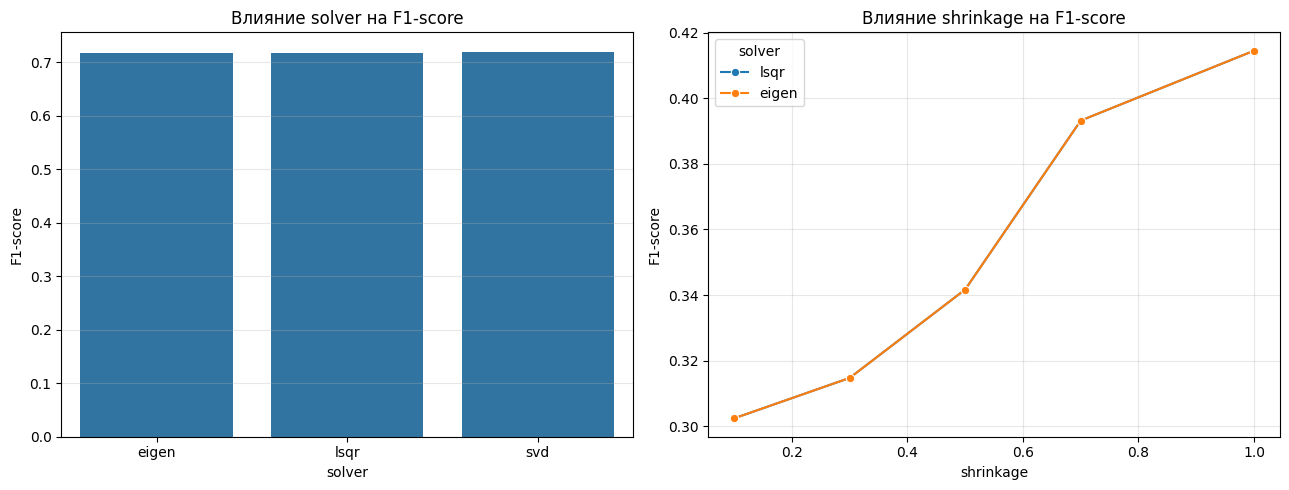

In [241]:
lda_cv_results = pd.DataFrame(grid_lda.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

solver_results = lda_cv_results.groupby(
    'param_solver'
)['mean_test_score'].max().reset_index()

sns.barplot(
    data=solver_results,
    x='param_solver',
    y='mean_test_score',
    ax=axes[0]
)

axes[0].set_title('Влияние solver на F1-score')
axes[0].set_xlabel('solver')
axes[0].set_ylabel('F1-score')
axes[0].grid(axis='y', alpha=0.3)

shrinkage_results = lda_cv_results[
    lda_cv_results['param_solver'].isin(['lsqr', 'eigen'])
].copy()

shrinkage_results = shrinkage_results[
    shrinkage_results['param_shrinkage'] != 'auto'
].copy()

shrinkage_results['param_shrinkage'] = (
    shrinkage_results['param_shrinkage'].astype(float)
)

sns.lineplot(
    data=shrinkage_results,
    x='param_shrinkage',
    y='mean_test_score',
    hue='param_solver',
    marker='o',
    ax=axes[1]
)

axes[1].set_title('Влияние shrinkage на F1-score')
axes[1].set_xlabel('shrinkage')
axes[1].set_ylabel('F1-score')
axes[1].legend(title='solver')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Вывод:** Исследование показало, что алгоритмы svd, lsqr и eigen обеспечивают практически одинаковое максимальное значение F1-score — около 0,720.

При использовании фиксированных значений shrinkage от 0,1 до 1,0 наблюдается увеличение F1-score приблизительно с 0,303 до 0,414. Однако полученные значения остаются значительно ниже максимального результата. Это указывает на то, что выбранные фиксированные коэффициенты регуляризации не обеспечивают оптимального качества классификации.

По результатам GridSearchCV лучшей признана комбинация solver = svd и shrinkage = None, при которой средний F1-score на кросс-валидации составил 0,720.

### Оценка оптимизированной модели LDA

In [242]:
lda_best = grid_lda.best_estimator_

y_pred_lda_best = lda_best.predict(X_test)
y_proba_lda_best = lda_best.predict_proba(X_test)[:, 1]

lda_best_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_lda_best),
    'Precision': precision_score(y_test, y_pred_lda_best),
    'Recall': recall_score(y_test, y_pred_lda_best),
    'F1-score': f1_score(y_test, y_pred_lda_best),
    'ROC-AUC': roc_auc_score(y_test, y_proba_lda_best)
}

lda_comparison = pd.DataFrame({
    'До оптимизации': lda_metrics,
    'После оптимизации': lda_best_metrics
}).T

display(lda_comparison.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
До оптимизации,0.765,0.721,0.638,0.677,0.838
После оптимизации,0.765,0.721,0.638,0.677,0.838


**Вывод:** В результате подбора гиперпараметров LDA оптимальной оказалась исходная конфигурация модели: solver = svd, shrinkage = None. Среднее значение F1-score на кросс-валидации составило 0,720.

Сравнение качества классификации на тестовой выборке показало, что все метрики остались неизменными: Accuracy = 0,765, Precision = 0,721, Recall = 0,638, F1-score = 0,677 и ROC-AUC = 0,838.

Таким образом, исследование не выявило комбинации гиперпараметров, обеспечивающей более высокое качество классификации по сравнению с исходной моделью. Использование алгоритма svd без регуляризации оказалось наиболее предпочтительным среди рассмотренных вариантов.

# Подбор гиперпараметров SVM

Метод опорных векторов (SVM) обладает несколькими гиперпараметрами, определяющими сложность разделяющей границы и способность модели обобщать данные.

В рамках исследования рассматриваются следующие гиперпараметры:

- **C** — параметр регуляризации, определяющий величину штрафа за ошибки классификации. При небольших значениях C допускается больше нарушений разделяющей границы, что способствует регуляризации модели. При больших значениях штраф за ошибки возрастает, увеличивая риск переобучения.
- **kernel** — тип ядра, определяющий способ построения разделяющей границы:
  - **linear** — линейное ядро, формирующее линейную границу между классами;
  - **rbf** — радиальное базисное ядро, позволяющее строить нелинейные границы;
  - **poly** — полиномиальное ядро, учитывающее нелинейные зависимости между признаками.
- **gamma** — коэффициент ядра, определяющий влияние отдельных обучающих объектов на форму разделяющей границы. Применяется для ядер rbf и poly. При небольших значениях влияние объектов распространяется на большую область, а при больших граница может становиться более сложной.

Для исследования выбраны следующие значения:

| Гиперпараметр | Исследуемые значения |
|---|---|
| C | 0.01, 0.1, 1, 10|
| kernel | linear, rbf, poly |
| gamma | scale, 0.001, 0.01, 0.1, 1 |

Для линейного ядра параметр gamma не используется, поэтому его влияние исследуется только для ядер rbf и poly.

In [243]:
param_grid_svm = [
    {
        'svc__kernel': ['linear'],
        'svc__C': [0.01, 0.1, 1, 10]
    },
    {
        'svc__kernel': ['rbf'],
        'svc__C': [0.01, 0.1, 1, 10],
        'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1]
    },
    {
        'svc__kernel': ['poly'],
        'svc__C': [0.01, 0.1, 1, 10],
        'svc__gamma': ['scale', 0.001, 0.01, 0.1]
    }
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

grid_svm = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        SVC(random_state=67, max_iter=10000)
    ),
    param_grid_svm,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_svm.fit(X_train, y_train)

print("Лучшие параметры:", grid_svm.best_params_)
print("Лучший F1-score (CV):", round(grid_svm.best_score_, 3))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Лучшие параметры: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Лучший F1-score (CV): 0.75


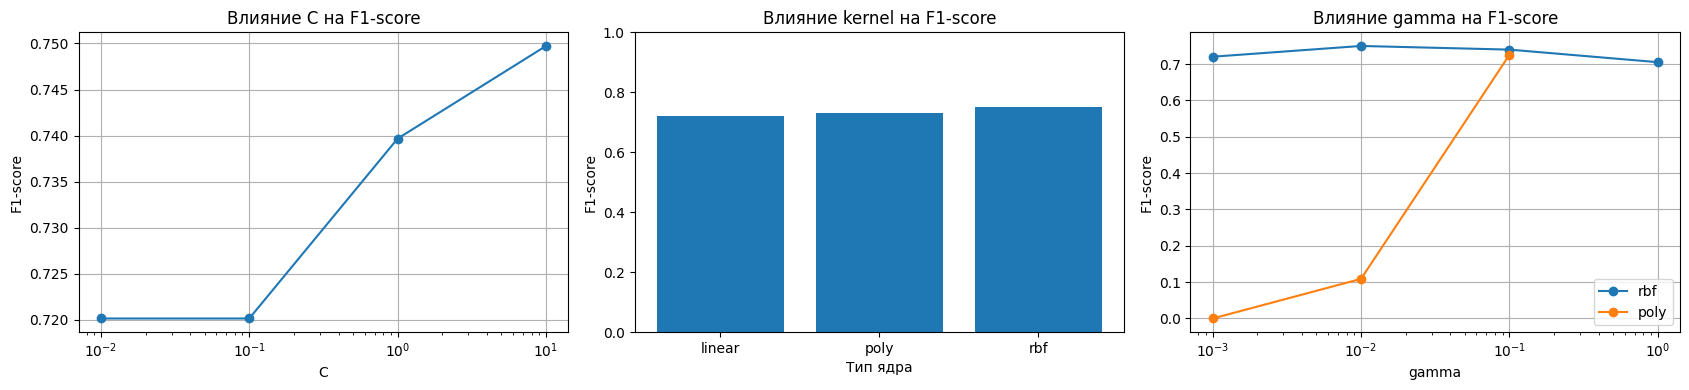

In [244]:
svm_cv_results = pd.DataFrame(grid_svm.cv_results_)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))


c_scores = svm_cv_results.groupby('param_svc__C')['mean_test_score'].max()

axes[0].plot(c_scores.index.astype(float), c_scores.values, marker='o')
axes[0].set_xscale('log')
axes[0].set_title('Влияние C на F1-score')
axes[0].set_xlabel('C')
axes[0].set_ylabel('F1-score')
axes[0].grid(True)


kernel_scores = svm_cv_results.groupby('param_svc__kernel')['mean_test_score'].max()

axes[1].bar(kernel_scores.index, kernel_scores.values)
axes[1].set_title('Влияние kernel на F1-score')
axes[1].set_xlabel('Тип ядра')
axes[1].set_ylabel('F1-score')
axes[1].set_ylim(0, 1)

for kernel in ['rbf', 'poly']:
    subset = svm_cv_results[
        (svm_cv_results['param_svc__kernel'] == kernel) &
        (svm_cv_results['param_svc__gamma'] != 'scale')
    ].copy()

    subset['gamma'] = subset['param_svc__gamma'].astype(float)
    gamma_scores = subset.groupby('gamma')['mean_test_score'].max()

    axes[2].plot(
        gamma_scores.index,
        gamma_scores.values,
        marker='o',
        label=kernel
    )

axes[2].set_xscale('log')
axes[2].set_title('Влияние gamma на F1-score')
axes[2].set_xlabel('gamma')
axes[2].set_ylabel('F1-score')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Вывод:** Исследование показало, что гиперпараметры C, kernel и gamma оказывают влияние на качество классификации SVM.

С увеличением C от 0,01 до 10 максимальное значение F1-score возрастает с 0,720 до 0,750. Среди рассмотренных типов ядер наилучший результат обеспечивает rbf. Для данного ядра качество классификации остаётся относительно стабильным при изменении gamma, тогда как полиномиальное ядро демонстрирует более выраженную чувствительность к этому параметру.

По результатам GridSearchCV оптимальной оказалась комбинация C = 10, kernel = rbf и gamma = 0,01. Среднее значение F1-score на кросс-валидации составило 0,750.

### Оценка оптимизированной модели SVM

In [245]:
svm_best = grid_svm.best_estimator_

y_pred_svm_best = svm_best.predict(X_test)
y_score_svm_best = svm_best.decision_function(X_test)

svm_best_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_svm_best),
    'Precision': precision_score(y_test, y_pred_svm_best),
    'Recall': recall_score(y_test, y_pred_svm_best),
    'F1-score': f1_score(y_test, y_pred_svm_best),
    'ROC-AUC': roc_auc_score(y_test, y_score_svm_best)
}

svm_comparison = pd.DataFrame({
    'До оптимизации': svm_metrics,
    'После оптимизации': svm_best_metrics
}).T

display(svm_comparison.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
До оптимизации,0.782,0.759,0.638,0.693,0.838
После оптимизации,0.782,0.742,0.667,0.702,0.830


**Вывод:** В результате подбора гиперпараметров SVM оптимальной оказалась конфигурация C = 10, kernel = rbf, gamma = 0,01. Среднее значение F1-score на кросс-валидации составило 0,750.

После оптимизации значение Accuracy осталось неизменным (0,782), Recall увеличился с 0,638 до 0,667, а F1-score — с 0,693 до 0,702. При этом Precision снизился с 0,759 до 0,742, а ROC-AUC — с 0,838 до 0,830.

Таким образом, оптимизация позволила немного улучшить баланс между полнотой и точностью классификации, однако не обеспечила улучшения по всем метрикам. Оптимизированная модель является предпочтительной по выбранному критерию F1-score.

### Подбор гиперпараметров kNN

Метод k ближайших соседей (kNN) выполняет классификацию объекта на основании классов наиболее близких к нему объектов обучающей выборки.

Качество классификации зависит от следующих гиперпараметров:

- **n_neighbors** — количество ближайших соседей, участвующих в классификации. Малые значения делают модель чувствительной к отдельным наблюдениям и шуму, а большие обеспечивают более сглаженную границу разделения классов.
- **weights** — способ учёта голосов соседей:
  - **uniform** — все соседи имеют одинаковый вес;
  - **distance** — более близкие соседи оказывают большее влияние на результат классификации.
- **p** — параметр метрики Минковского, определяющий способ вычисления расстояния между объектами:
  - **p = 1** — манхэттенское расстояние;
  - **p = 2** — евклидово расстояние.

Расстояние Минковского вычисляется по формуле:

$$
d(x,y) = \left(\sum_{i=1}^{n} |x_i-y_i|^p\right)^{\frac{1}{p}}
$$

Для исследования выбраны следующие значения гиперпараметров:

| Гиперпараметр | Исследуемые значения |
|---|---|
| n_neighbors | 3, 5, 7, 9, 11, 15, 21, 31 |
| weights | uniform, distance |
| p | 1, 2 |


In [246]:
param_grid_knn = {
    'kneighborsclassifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
    'kneighborsclassifier__weights': ['uniform', 'distance'],
    'kneighborsclassifier__p': [1, 2]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

grid_knn = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    ),
    param_grid_knn,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Лучшие параметры:", grid_knn.best_params_)
print("Лучший F1-score (CV):", round(grid_knn.best_score_, 3))

Лучшие параметры: {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'uniform'}
Лучший F1-score (CV): 0.727


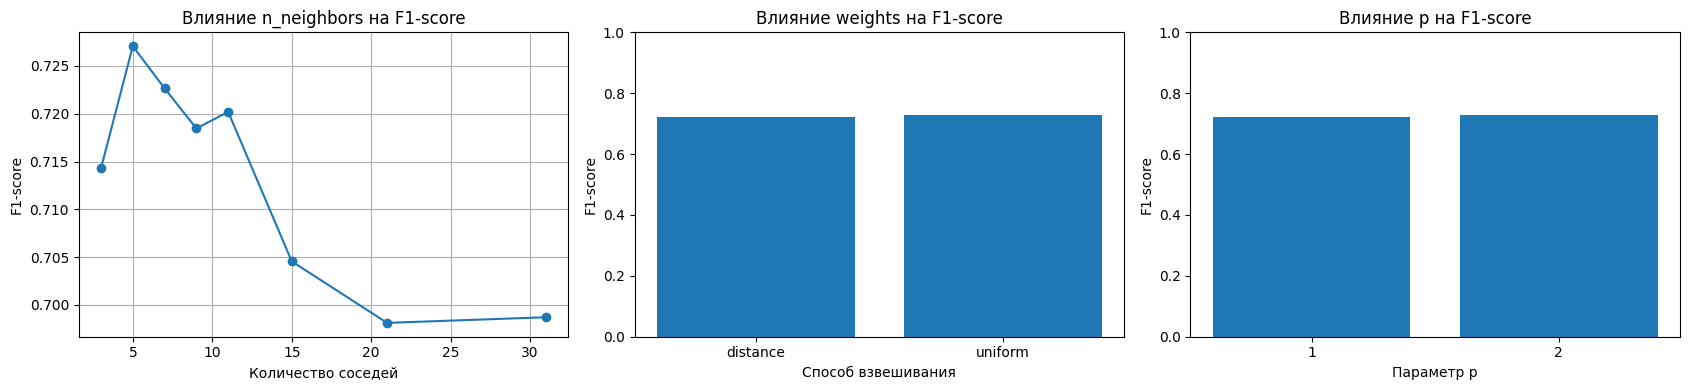

In [247]:
knn_cv_results = pd.DataFrame(grid_knn.cv_results_)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))


neighbors_scores = knn_cv_results.groupby(
    'param_kneighborsclassifier__n_neighbors'
)['mean_test_score'].max()

axes[0].plot(
    neighbors_scores.index.astype(int),
    neighbors_scores.values,
    marker='o'
)
axes[0].set_title('Влияние n_neighbors на F1-score')
axes[0].set_xlabel('Количество соседей')
axes[0].set_ylabel('F1-score')
axes[0].grid(True)


weights_scores = knn_cv_results.groupby(
    'param_kneighborsclassifier__weights'
)['mean_test_score'].max()

axes[1].bar(weights_scores.index, weights_scores.values)
axes[1].set_title('Влияние weights на F1-score')
axes[1].set_xlabel('Способ взвешивания')
axes[1].set_ylabel('F1-score')
axes[1].set_ylim(0, 1)


p_scores = knn_cv_results.groupby(
    'param_kneighborsclassifier__p'
)['mean_test_score'].max()

axes[2].bar(p_scores.index.astype(str), p_scores.values)
axes[2].set_title('Влияние p на F1-score')
axes[2].set_xlabel('Параметр p')
axes[2].set_ylabel('F1-score')
axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Вывод:** Исследование показало, что наибольшее влияние на качество классификации kNN оказывает количество ближайших соседей. Максимальное значение F1-score = 0,727 достигается при n_neighbors = 5. При дальнейшем увеличении количества соседей наблюдается снижение качества классификации.

Способ взвешивания и метрика расстояния оказывают менее выраженное влияние. Равномерное взвешивание (uniform) и евклидово расстояние (p = 2) обеспечивают немного более высокие значения F1-score.

По результатам GridSearchCV оптимальной оказалась комбинация n_neighbors = 5, weights = uniform, p = 2. Среднее значение F1-score на кросс-валидации составило 0,727.

### Оценка оптимизированной модели k-Nearest Neighbors

In [248]:
knn_best = grid_knn.best_estimator_

y_pred_knn_best = knn_best.predict(X_test)
y_proba_knn_best = knn_best.predict_proba(X_test)[:, 1]

knn_best_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_knn_best),
    'Precision': precision_score(y_test, y_pred_knn_best),
    'Recall': recall_score(y_test, y_pred_knn_best),
    'F1-score': f1_score(y_test, y_pred_knn_best),
    'ROC-AUC': roc_auc_score(y_test, y_proba_knn_best)
}

knn_comparison = pd.DataFrame({
    'До оптимизации': knn_metrics,
    'После оптимизации': knn_best_metrics
}).T

display(knn_comparison.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
До оптимизации,0.788,0.782,0.623,0.694,0.818
После оптимизации,0.788,0.782,0.623,0.694,0.818


**Вывод:** В результате подбора гиперпараметров kNN оптимальной оказалась исходная конфигурация модели: n_neighbors = 5, weights = uniform, p = 2. Среднее значение F1-score на кросс-валидации составило 0,727.

Сравнение качества классификации на тестовой выборке показало, что все метрики остались неизменными: Accuracy = 0,788, Precision = 0,782, Recall = 0,623, F1-score = 0,694 и ROC-AUC = 0,818.

Таким образом, исследование не выявило комбинации гиперпараметров, обеспечивающей более высокое качество классификации по сравнению с исходной моделью. Использование пяти ближайших соседей, равномерного взвешивания и евклидова расстояния оказалось наиболее предпочтительным среди рассмотренных вариантов.

# Итоговый анализ результатов оптимизации классификаторов

In [249]:
optimized_results = pd.DataFrame({
    'GaussianNB': nb_best_metrics,
    'Decision Tree': dt_best_metrics,
    'LDA': lda_best_metrics,
    'SVM': svm_best_metrics,
    'kNN': knn_best_metrics
}).T

display(optimized_results.round(3))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
GaussianNB,0.832,0.800,0.754,0.776,0.865
Decision Tree,0.777,0.738,0.652,0.692,0.829
LDA,0.765,0.721,0.638,0.677,0.838
SVM,0.782,0.742,0.667,0.702,0.830
kNN,0.788,0.782,0.623,0.694,0.818


<Figure size 1200x600 with 0 Axes>

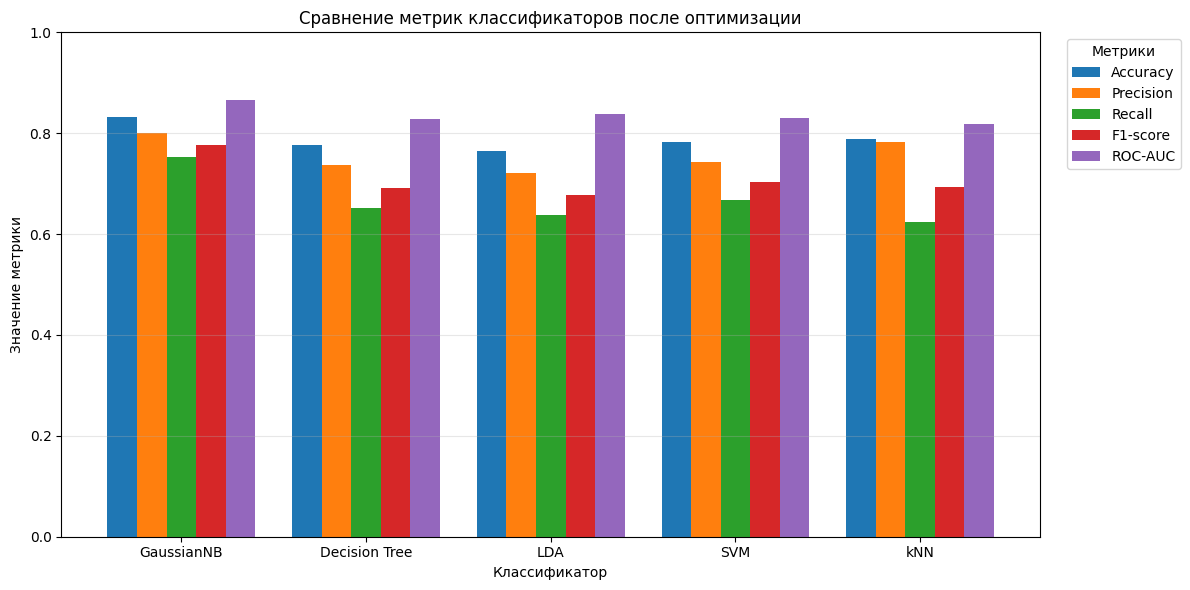

In [250]:
plt.figure(figsize=(12, 6))

optimized_results.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Сравнение метрик классификаторов после оптимизации')
plt.xlabel('Классификатор')
plt.ylabel('Значение метрики')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title='Метрики', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

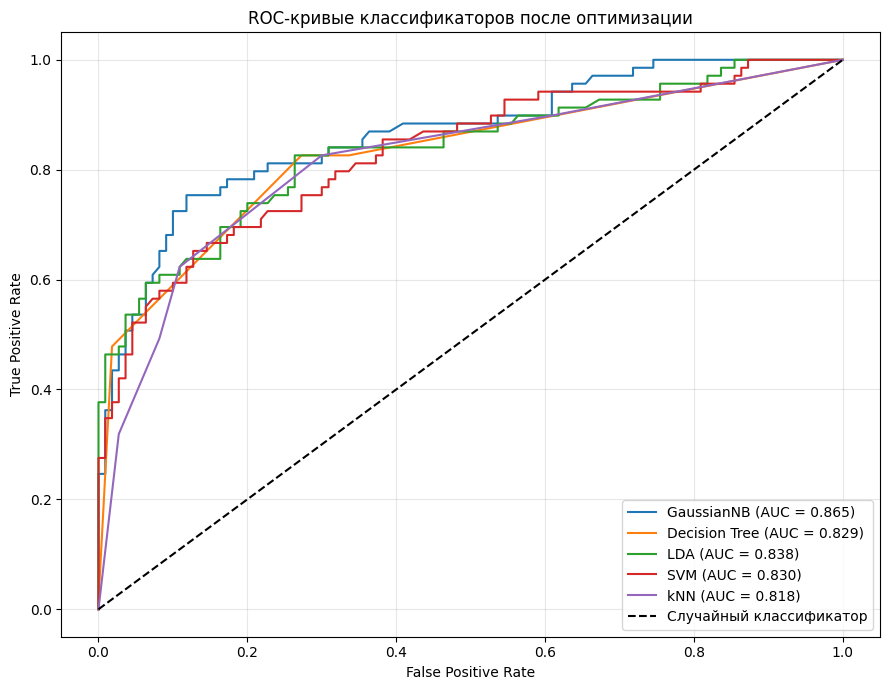

In [251]:
models_roc = {
    'GaussianNB': y_proba_nb_best,
    'Decision Tree': y_proba_dt_best,
    'LDA': y_proba_lda_best,
    'SVM': y_score_svm_best,
    'kNN': y_proba_knn_best
}

plt.figure(figsize=(9, 7))

for name, scores in models_roc.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор')

plt.title('ROC-кривые классификаторов после оптимизации')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Был выполнен подбор гиперпараметров пяти алгоритмов классификации: GaussianNB, Decision Tree, LDA, SVM и kNN. Для поиска оптимальных параметров использовался GridSearchCV с пятиблочной стратифицированной кросс-валидацией. Основным критерием оптимизации являлась метрика F1-score.

По результатам экспериментов установлено следующее:

1. **GaussianNB** показал наилучшее качество классификации среди всех исследованных алгоритмов. После оптимизации F1-score увеличился с 0,770 до 0,776, а Accuracy — с 0,827 до 0,832. Модель также продемонстрировала наибольшие значения Precision (0,800), Recall (0,754) и ROC-AUC (0,865).

2. **Decision Tree** продемонстрировало улучшение F1-score с 0,677 до 0,692 и ROC-AUC с 0,740 до 0,829. Ограничение максимальной глубины дерева до трёх уровней позволило существенно сократить разницу между качеством на обучающей и тестовой выборках, уменьшив признаки переобучения.

3. **LDA** сохранил исходные показатели качества: F1-score = 0,677 и ROC-AUC = 0,838. Оптимальной оказалась конфигурация по умолчанию, поэтому подбор гиперпараметров не привёл к улучшению результатов.

4. **SVM** после оптимизации показал увеличение F1-score с 0,693 до 0,702 и Recall с 0,638 до 0,667. Однако Precision и ROC-AUC несколько снизились, что свидетельствует о наличии компромисса между отдельными показателями качества.

5. **kNN** сохранил исходные показатели качества: F1-score = 0,694 и ROC-AUC = 0,818. Наилучшей среди рассмотренных комбинаций оказалась конфигурация по умолчанию с пятью ближайшими соседями, равномерным взвешиванием и евклидовым расстоянием.

**Таким образом, оптимизация гиперпараметров позволила повысить F1-score у трёх из пяти классификаторов.** Наиболее заметное улучшение наблюдалось у Decision Tree, для которого также удалось уменьшить признаки переобучения.

**Наилучшей моделью для рассматриваемого набора данных Titanic оказался GaussianNB**, продемонстрировавший максимальные значения всех пяти метрик на тестовой выборке. Следовательно, среди исследованных классических алгоритмов GaussianNB можно рекомендовать для решения поставленной задачи бинарной классификации.